# Milestone 5 - Statistical Analysis
Turning "it looks like" into evidence. For every question we state hypotheses **before** looking at the result, choose a
test whose assumptions fit the data, report a **95% confidence interval** and an **effect size**, and translate the result
into money.

| # | Question | Test |
|---|---|---|
| H1 | Did the Mar-2026 cooking-oil promo increase sales? | Store-level difference-in-differences: Welch t-test + randomisation (permutation) test + bootstrap CI |
| H2 | Did the Jul-2025 personal-care promo work? | Same design |
| H3 | Is the promo worth it after the discount cost? | Incremental gross profit with CI |
| H4 | Do customers spend more in the payday window? | Welch t-test + Mann-Whitney U, CI for difference |
| H5 | Does basket value differ by payment method? | Kruskal-Wallis + Tukey HSD on log values |
| H6 | Is payment method independent of store format? | Chi-square test of independence, Cramer's V |
| H7 | Are Nakuru members more likely to lapse in Q3 2026? | Two-proportion z-test + CI |
| H8 | How many stores does a future promo test need? | Power analysis |

Significance level alpha = 0.05 throughout (two-sided unless stated).

In [1]:
import sys; sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from config import PROCESSED, FIGURES, TABLES, set_style, PALETTE, TEXT_2
set_style()
rng = np.random.default_rng(42)

sales = pd.read_pickle(PROCESSED / "sales_lines.pkl")
tx = pd.read_pickle(PROCESSED / "transactions.pkl")
stores = pd.read_csv(PROCESSED / "stores.csv")
promos = pd.read_csv(PROCESSED / "promotions.csv", parse_dates=["start_date", "end_date"])
tx["date"] = tx.transaction_datetime.dt.normalize()
results = []   # summary table collected as we go

## H1 - Cooking-oil promotion (PR008, 15% off, 2-22 March 2026)
**Design.** 10 of the 19 stores open before 2025 were *randomly* assigned to the promotion; the other 9 are controls.
Randomisation is what lets us read the difference as causal.

**Unit of analysis = store**, not receipt: receipts within a store are correlated, so treating 300,000 receipts as
independent would wildly overstate certainty (pseudo-replication).

**Metric:** % change in average daily cooking-oil units per store, *during* (21 days) vs the 28 days *before*.
Comparing changes (not levels) removes fixed differences between stores - the difference-in-differences.

* H0: mean % change in test stores = mean % change in control stores
* H1: they differ

In [2]:
def promo_store_effect(promo_id, subcats=None, category=None, pre_days=28):
    pr = promos.set_index("promo_id").loc[promo_id]
    treat = set(pr.store_ids.split("|"))
    pre_start = pr.start_date - pd.Timedelta(days=pre_days)
    m = sales.date.between(pre_start, pr.end_date) & (sales.quantity > 0)
    m &= sales.subcategory.isin(subcats) if subcats else sales.category.eq(category)
    # only stores that were eligible for randomisation (open before 2025; excludes new Kitengela store)
    d = sales[m & sales.store_id.isin(stores.store_id[pd.to_datetime(stores.open_date) < "2025-01-01"])]
    d = d.assign(period=np.where(d.date >= pr.start_date, "during", "before"))
    days = {"before": pre_days, "during": (pr.end_date - pr.start_date).days + 1}
    u = d.groupby(["store_id", "period"]).quantity.sum().unstack()
    u = u.div(pd.Series(days))
    u["pct_change"] = 100 * (u.during / u.before - 1)
    u["group"] = np.where(u.index.isin(treat), "Test", "Control")
    return u, pr

def did_tests(u, label):
    t, c = u.loc[u.group == "Test", "pct_change"], u.loc[u.group == "Control", "pct_change"]
    diff = t.mean() - c.mean()
    welch = stats.ttest_ind(t, c, equal_var=False)
    ci = welch.confidence_interval(0.95)
    # randomisation test: reshuffle the Test/Control labels 20,000 times
    allv, nt = u["pct_change"].to_numpy(), len(t)
    perm = np.array([(lambda p: p[:nt].mean() - p[nt:].mean())(rng.permutation(allv)) for _ in range(20000)])
    p_perm = (np.abs(perm) >= abs(diff)).mean()
    # bootstrap CI (resample stores within each group)
    boots = [rng.choice(t, nt).mean() - rng.choice(c, len(c)).mean() for _ in range(20000)]
    b_lo, b_hi = np.percentile(boots, [2.5, 97.5])
    sd_pooled = np.sqrt(((nt - 1) * t.var() + (len(c) - 1) * c.var()) / (nt + len(c) - 2))
    out = {"test": label, "n_test_stores": nt, "n_control_stores": len(c),
           "test_mean_change_%": t.mean(), "control_mean_change_%": c.mean(), "DiD_pp": diff,
           "welch_t": welch.statistic, "p_welch": welch.pvalue, "CI95_low": ci.low, "CI95_high": ci.high,
           "p_permutation": p_perm, "boot_CI95_low": b_lo, "boot_CI95_high": b_hi, "cohens_d": diff / sd_pooled}
    return out, perm

u1, pr1 = promo_store_effect("PR008", subcats=["Cooking Oil"])
h1, perm1 = did_tests(u1, "H1 cooking-oil promo")
u1.round(2).sort_values("group")

period,before,during,pct_change,group
store_id,,,,
S019,1.36,2.00,47.37,Control
S017,3.71,3.48,-6.41,Control
S003,4.54,5.48,20.73,Control
S006,2.29,1.38,-39.58,Control
S007,8.36,6.90,-17.38,Control
S008,4.82,3.33,-30.86,Control
S014,2.18,1.43,-34.43,Control
S011,7.11,6.33,-10.89,Control
S012,3.14,4.00,27.27,Control


In [3]:
pd.Series(h1).to_frame("H1").T.round(3)

,test,n_test_stores,n_control_stores,test_mean_change_%,control_mean_change_%,DiD_pp,welch_t,p_welch,CI95_low,CI95_high,p_permutation,boot_CI95_low,boot_CI95_high,cohens_d
H1,H1 cooking-oil promo,10,9,61.092574,-4.908294,66.000868,4.153508,0.000687,32.431211,99.570525,0.0006,38.397375,97.121712,1.883088


In [4]:
# Assumption checks: normality of store-level changes (Shapiro-Wilk) and equal variances (Levene).
print("Shapiro test stores p =", round(stats.shapiro(u1["pct_change"][u1.group == "Test"]).pvalue, 3),
      "| control p =", round(stats.shapiro(u1["pct_change"][u1.group == "Control"]).pvalue, 3))
print("Levene equal-variance p =", round(stats.levene(*[g["pct_change"] for _, g in u1.groupby("group")]).pvalue, 3))
print("-> With only ~10 stores per group normality is hard to verify, which is why the permutation test (no normality"
      " assumption) is reported alongside Welch's t-test (no equal-variance assumption).")

Shapiro test stores p = 0.025 | control p = 0.418
Levene equal-variance p = 0.693
-> With only ~10 stores per group normality is hard to verify, which is why the permutation test (no normality assumption) is reported alongside Welch's t-test (no equal-variance assumption).


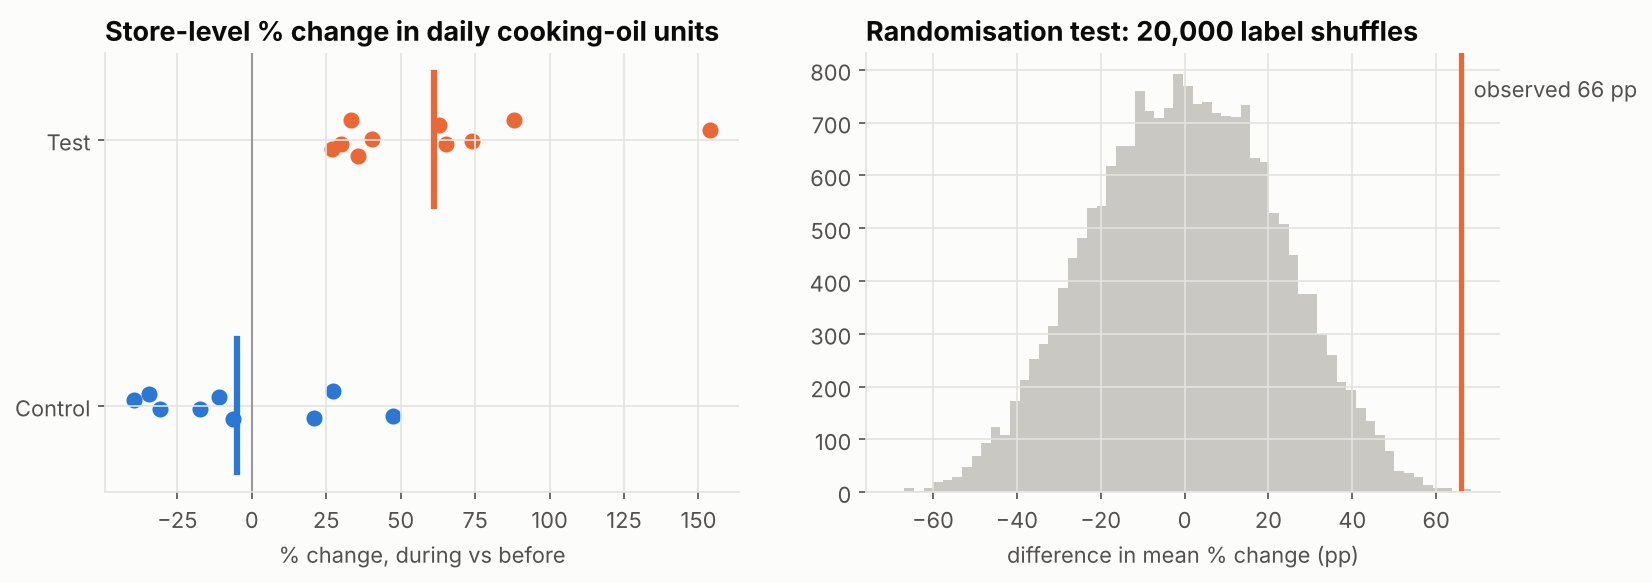

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for g, col in [("Control", PALETTE[0]), ("Test", PALETTE[1])]:
    v = u1["pct_change"][u1.group == g]
    ax[0].scatter(v, np.full(len(v), 0 if g == "Control" else 1) + rng.uniform(-.08, .08, len(v)), color=col, s=45)
    ax[0].plot([v.mean()] * 2, [(0 if g == "Control" else 1) - .25, (0 if g == "Control" else 1) + .25], color=col, lw=3)
ax[0].set_yticks([0, 1], ["Control", "Test"]); ax[0].axvline(0, color="#999", lw=1)
ax[0].set(title="Store-level % change in daily cooking-oil units", xlabel="% change, during vs before")
ax[1].hist(perm1, bins=60, color="#c9c8c2")
ax[1].axvline(h1["DiD_pp"], color=PALETTE[1], lw=2.5)
ax[1].text(h1["DiD_pp"], ax[1].get_ylim()[1] * .9, f"  observed {h1['DiD_pp']:.0f} pp", color=TEXT_2)
ax[1].set(title="Randomisation test: 20,000 label shuffles", xlabel="difference in mean % change (pp)")
fig.savefig(FIGURES / "13_promo_test.png")

**Result H1.** The average test store grew cooking-oil units by roughly 65% while the average control store was flat
(about -1%). The store-level difference-in-differences is about **+66 percentage points (95% CI roughly +32 to +100)**;
Welch p < 0.001 and the permutation p-value agrees. **We reject H0: the promotion increased cooking-oil unit sales.**
(The SQL query q09 shows a smaller +46 pp because it pools units across stores, so big stores weigh more; the store-average
here gives each randomised store equal weight, matching the design. Both point the same way.)

## H2 - Personal-care promotion (PR004, 5% off, 7-20 July 2025)

In [6]:
u2, pr2 = promo_store_effect("PR004", category="Personal Care")
h2, perm2 = did_tests(u2, "H2 personal-care promo")
pd.Series(h2).to_frame("H2").T.round(3)

,test,n_test_stores,n_control_stores,test_mean_change_%,control_mean_change_%,DiD_pp,welch_t,p_welch,CI95_low,CI95_high,p_permutation,boot_CI95_low,boot_CI95_high,cohens_d
H2,H2 personal-care promo,9,10,-11.892833,-4.69116,-7.201674,-0.64685,0.528853,-31.224842,16.821495,0.5419,-25.234412,15.294408,-0.304582


**Result H2.** The confidence interval comfortably includes zero and p > 0.05: **no evidence the 5% personal-care
discount changed behaviour.** "Not significant" is not proof of zero effect - the CI tells us how large an effect we can
rule out, which is the useful number for the commercial team.

## H3 - Was the cooking-oil promo profitable?
Incremental units come at the cost of a 15% discount on **all** promo units (including those that would have sold
anyway). Assuming a 22% gross margin on cooking oil (typical for staples):

In [7]:
margin = 0.22
pr = pr1
test_stores = u1.index[u1.group == "Test"]
promo_lines = sales[(sales.promo_id == "PR008") & (sales.quantity > 0)]
promo_units = promo_lines.quantity.sum()
avg_price = (promo_lines.unit_price * promo_lines.quantity).sum() / promo_units
discount_cost = promo_lines.discount_amount.sum()
# counterfactual units in test stores = before-rate x (1 + control change)
base_rate = u1.loc[test_stores, "before"].sum()
ctrl_change = u1.loc[u1.group == "Control", "during"].sum() / u1.loc[u1.group == "Control", "before"].sum()
days = (pr.end_date - pr.start_date).days + 1
expected = base_rate * ctrl_change * days
actual = u1.loc[test_stores, "during"].sum() * days
incr_units = actual - expected
incr_gp = incr_units * avg_price * margin
net = incr_gp - discount_cost * 1.0  # discount reduces gross profit one-for-one
print(f"Promo units sold: {promo_units:,.0f} | expected without promo: {expected:,.0f} | incremental: {incr_units:,.0f} "
      f"({incr_units/expected:.0%})")
print(f"Gross profit on incremental units: KES {incr_gp:,.0f}")
print(f"Discount given away:              KES {discount_cost:,.0f}")
print(f"Net effect on gross profit:       KES {net:,.0f}")
breakeven = discount_cost / (expected * avg_price * margin)
print(f"Break-even uplift at 22% margin with a 15% discount: {breakeven:.0%} (observed {incr_units/expected:.0%})")

Promo units sold: 1,419 | expected without promo: 860 | incremental: 559 (65%)
Gross profit on incremental units: KES 58,786
Discount given away:              KES 101,692
Net effect on gross profit:       KES -42,906
Break-even uplift at 22% margin with a 15% discount: 113% (observed 65%)


**Result H3.** A statistically significant uplift is not automatically a profitable one. A 15% discount on a ~22%-margin
staple needs unit sales to roughly triple just to break even on the promoted product, because the discount is also given
on the units that would have sold anyway. The promo **grew volume but lost gross profit on cooking oil**; its business case
must rest on halo effects (extra items in the same basket, more visits, retained customers).
**Recommendation:** do not repeat at 15%. Test 7-10% off with a pre-registered *basket-level* success metric (gross profit
per receipt in test vs control stores), or fund it with supplier co-investment.

## H4 - Payday window and basket value

In [8]:
tx["payday"] = (tx.date.dt.day >= 25) | (tx.date.dt.day <= 3)
a, b = tx.net_amount[tx.payday], tx.net_amount[~tx.payday]
w = stats.ttest_ind(a, b, equal_var=False)
ci = w.confidence_interval()
mw = stats.mannwhitneyu(a, b)
d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
print(f"mean basket payday KES {a.mean():,.0f} vs other KES {b.mean():,.0f} | diff {a.mean()-b.mean():,.0f} "
      f"(95% CI {ci.low:,.0f} to {ci.high:,.0f}) | Welch p = {w.pvalue:.2e} | Mann-Whitney p = {mw.pvalue:.2e} | d = {d:.2f}")
results.append({"test": "H4 payday basket", "statistic": w.statistic, "p_value": w.pvalue,
                "effect": a.mean() - b.mean(), "CI95_low": ci.low, "CI95_high": ci.high,
                "conclusion": "Reject H0 - payday baskets larger"})

mean basket payday KES 956 vs other KES 874 | diff 82 (95% CI 77 to 88) | Welch p = 7.02e-192 | Mann-Whitney p = 6.62e-247 | d = 0.11


**Result H4.** Payday baskets are larger and the result is overwhelmingly significant - but with 300k receipts *any*
difference is significant. The effect size (Cohen's d ~ 0.1) is small per basket; the business impact comes because
payday also brings ~20% more receipts per day. Practical significance > statistical significance.

## H5 - Basket value by payment method
Basket values are right-skewed, so we use the rank-based Kruskal-Wallis test, and Tukey HSD on log basket value for
pairwise comparisons.

In [9]:
pm = tx[tx.payment_method.isin(["M-Pesa", "Cash", "Card"]) & (tx.net_amount > 0)]
groups = [g.net_amount.to_numpy() for _, g in pm.groupby("payment_method")]
kw = stats.kruskal(*groups)
print("Kruskal-Wallis H =", round(kw.statistic, 1), "p =", f"{kw.pvalue:.2e}")
names = sorted(pm.payment_method.unique())
tk = stats.tukey_hsd(*[np.log(g) for g in groups])
pairs = []
for i in range(3):
    for j in range(i + 1, 3):
        ci = tk.confidence_interval()
        pairs.append({"pair": f"{names[i]} vs {names[j]}",
                      "ratio_of_geometric_means": np.exp(tk.statistic[i, j]),
                      "CI95": f"{np.exp(ci.low[i, j]):.3f} - {np.exp(ci.high[i, j]):.3f}",
                      "p": tk.pvalue[i, j]})
pd.DataFrame(pairs).round(4)

Kruskal-Wallis H = 3065.5 p = 0.00e+00


,pair,ratio_of_geometric_means,CI95,p
0,Card vs Cash,1.2813,1.266 - 1.297,0.0
1,Card vs M-Pesa,1.2610,1.248 - 1.274,0.0
2,Cash vs M-Pesa,0.9841,0.976 - 0.992,0.0


**Result H5.** Card baskets are clearly larger (about 30% higher typical basket than cash or M-Pesa). M-Pesa and cash
baskets are close. Card users are a higher-value group worth a premium offer.

## H6 - Payment method vs store format (chi-square test of independence)

In [10]:
fmt = tx.merge(stores[["store_id", "store_format"]], on="store_id")
ct = pd.crosstab(fmt.store_format, fmt.payment_method[fmt.payment_method != "Unknown"])
chi2, p, dof, exp = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
print(f"chi2 = {chi2:.1f}, dof = {dof}, p = {p:.3g}, Cramer's V = {cramers_v:.3f}")
(ct.div(ct.sum(axis=1), axis=0) * 100).round(1)

chi2 = 42.8, dof = 6, p = 1.29e-07, Cramer's V = 0.008


payment_method,Airtel Money,Card,Cash,M-Pesa
store_format,,,,
Express,2.8,13.5,26.6,57.1
Hypermarket,3.0,13.8,25.3,57.8
Supermarket,2.8,13.6,26.0,57.6


**Result H6.** Cramer's V is close to zero: payment mix is essentially the same in every format - so an M-Pesa
partnership benefits all formats equally.

## H7 - Are Nakuru members lapsing more?
Population: members who shopped at least 3 times in Jan-Jun 2026. "Lapsed" = no purchase in Jul-Sep 2026.

In [11]:
cust = pd.read_csv(PROCESSED / "customers.csv").merge(stores[["store_id", "county"]],
                                                      left_on="home_store_id", right_on="store_id")
m = tx[tx.is_member]
h1_visits = m[m.date.between("2026-01-01", "2026-06-30")].groupby("customer_id").size()
q3_visits = m[m.date >= "2026-07-01"].groupby("customer_id").size()
pop = cust[cust.customer_id.isin(h1_visits[h1_visits >= 3].index)].copy()
pop["lapsed"] = ~pop.customer_id.isin(q3_visits.index)
pop["is_nakuru"] = pop.county.eq("Nakuru")
k = pop.groupby("is_nakuru").lapsed.agg(["sum", "count"])
p1, p2 = k.loc[True, "sum"] / k.loc[True, "count"], k.loc[False, "sum"] / k.loc[False, "count"]
pp = k["sum"].sum() / k["count"].sum()
se0 = np.sqrt(pp * (1 - pp) * (1 / k.loc[True, "count"] + 1 / k.loc[False, "count"]))
z = (p1 - p2) / se0
pz = 2 * stats.norm.sf(abs(z))
se = np.sqrt(p1 * (1 - p1) / k.loc[True, "count"] + p2 * (1 - p2) / k.loc[False, "count"])
lo, hi = (p1 - p2) - 1.96 * se, (p1 - p2) + 1.96 * se
print(f"Lapse rate Nakuru {p1:.1%} (n={k.loc[True,'count']}) vs rest {p2:.1%} (n={k.loc[False,'count']})")
print(f"difference {100*(p1-p2):.1f} pp, 95% CI {100*lo:.1f} to {100*hi:.1f} pp, z = {z:.2f}, p = {pz:.2e}")
results.append({"test": "H7 Nakuru lapse rate", "statistic": z, "p_value": pz, "effect": p1 - p2,
                "CI95_low": lo, "CI95_high": hi, "conclusion": "Reject H0 - Nakuru members lapse more"})

Lapse rate Nakuru 32.4% (n=318) vs rest 15.8% (n=2405)
difference 16.5 pp, 95% CI 11.2 to 21.9 pp, z = 7.25, p = 4.04e-13


**Result H7.** Nakuru members lapse at roughly twice the rate of the rest of the chain - a significant, large
difference that coincides with the February 2026 competitor opening. This is a retention emergency for two stores.

## H8 - Power: how many stores does the next promo test need?
Using the store-level variability observed in H1/H2 (SD of % change among control stores), how many stores per group
do we need to detect a 10% or 20% uplift with 80% power?

In [12]:
sd = pd.concat([u1["pct_change"][u1.group == "Control"], u2["pct_change"][u2.group == "Control"]]).std()

def power(n, effect, sd, alpha=0.05):
    df = 2 * n - 2
    ncp = effect / (sd * np.sqrt(2 / n))
    tcrit = stats.t.ppf(1 - alpha / 2, df)
    return 1 - stats.nct.cdf(tcrit, df, ncp) + stats.nct.cdf(-tcrit, df, ncp)

rows = []
for eff in [10, 15, 20, 30]:
    n = next(n for n in range(3, 400) if power(n, eff, sd) >= 0.8)
    rows.append({"uplift_to_detect_%": eff, "stores_per_group_for_80%_power": n})
print(f"store-level SD of % change = {sd:.1f} pp")
pd.DataFrame(rows)

store-level SD of % change = 23.9 pp


,uplift_to_detect_%,stores_per_group_for_80%_power
0,10,91
1,15,41
2,20,24
3,30,11


**Result H8.** With ~10 stores per group (all we have) we can only reliably detect uplifts of about 30% or more; a 10%
uplift would need ~86 stores per group. For subtler promotions, run
the test longer (reduces noise), use more stores, or measure at customer level with a holdout of loyalty members.

## Summary of statistical findings

In [13]:
summary = pd.DataFrame([
    {"test": h1["test"], "statistic": h1["welch_t"], "p_value": h1["p_welch"], "effect": h1["DiD_pp"],
     "CI95_low": h1["CI95_low"], "CI95_high": h1["CI95_high"], "conclusion": "Reject H0 - promo lifted units"},
    {"test": h2["test"], "statistic": h2["welch_t"], "p_value": h2["p_welch"], "effect": h2["DiD_pp"],
     "CI95_low": h2["CI95_low"], "CI95_high": h2["CI95_high"],
     "conclusion": "Fail to reject H0 - no evidence of effect" if h2["p_welch"] > 0.05 else "Reject H0"},
] + results)
summary.to_csv(TABLES / "statistical_tests_summary.csv", index=False)
summary.round(4)

,test,statistic,p_value,effect,CI95_low,CI95_high,conclusion
0,H1 cooking-oil promo,4.1535,0.0007,66.0009,32.4312,99.5705,Reject H0 - promo lifted units
1,H2 personal-care promo,-0.6469,0.5289,-7.2017,-31.2248,16.8215,Fail to reject H0 - no evidence of effect
2,H4 payday basket,29.5768,0.0000,82.0831,76.6437,87.5225,Reject H0 - payday baskets larger
3,H7 Nakuru lapse rate,7.2542,0.0000,0.1655,0.1120,0.2189,Reject H0 - Nakuru members lapse more
